# How robust is MiniRocket to noise and limited training data?

**Jacob Antonio and Uchhas Dewan, University College Dublin**

The MiniRocket paper evaluates accuracy on the UCR archive as distributed, but does not test how the method behaves when the data are noisier or the training sets smaller. This notebook documents an experiment addressing our third research question: how robust is MiniRocket to noise, series length and limited training data?

We ran the authors' unmodified MiniRocket under three kinds of change, one at a time:

1. **Noise.** Gaussian noise was added to every training and test series, with a standard deviation equal to 10%, 25% or 50% of that series' own standard deviation. Scaling the noise to each series keeps the difficulty comparable across datasets with very different value ranges.
2. **Limited training data.** The training set was reduced to 50% or 25% of its original size, sampling within each class and keeping at least one example per class. The test set was unchanged.
3. **Series length.** Rather than altering the data, we related each dataset's sensitivity to its series length. Section 4 checks whether longer or shorter series lose more accuracy under noise. MiniRocket's runtime scaling with length is covered separately by our DucksAndGeese experiment.

Every condition is compared with a clean run (no noise, full training set) carried out in this notebook with the same seeds, so the only difference between conditions is the change being tested.

**Setup.** We used the same 109 datasets, classifier and feature normalisation as our main reproduction. By default, only resample 0 (each dataset's original UCR split) is used. Further resamples can be added to `RESAMPLES`; these reuse the split indices saved by our UCR benchmark, so the examples match exactly. MiniRocket's internal random generator, the noise and the training subsets are all seeded, so every run is repeatable.

Results are saved after every dataset, so an interrupted run resumes where it stopped. With one resample, all six conditions take roughly 35 to 40 minutes on our machine. `DATASET_LIMIT = 3` gives a quick trial run.

## 1. Configuration and setup

In [1]:
from pathlib import Path
import importlib
import json
import platform
import sys
import time

import matplotlib.pyplot as plt
import numba
import numpy as np
import pandas as pd
from aeon.datasets import load_from_ts_file
from numba import njit
from scipy.stats import spearmanr, wilcoxon
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score
from threadpoolctl import threadpool_limits

# Project paths on the machine used for our runs (the same as in our UCR benchmark notebook)
PROJECT = Path("/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series")
REPO = PROJECT / "minirocket"
CODE_DIR = REPO / "code"
DATA_ROOT = PROJECT / "UCR Archive 2018"
REFERENCE_RESULTS = REPO / "results" / "accuracy_ucr109_resamples.csv"
UCR_SPLIT_DIR = PROJECT / "minirocket_ucr109_results" / "splits"

for required_path in (REPO, CODE_DIR, DATA_ROOT, REFERENCE_RESULTS):
    if not required_path.exists():
        raise FileNotFoundError(f"Required path not found: {required_path}")

# The authors' implementation, imported unmodified
sys.modules.pop("minirocket", None)
sys.path.insert(0, str(CODE_DIR))
importlib.invalidate_caches()
import minirocket

# One CPU thread, as in our reproduction
numba.set_num_threads(1)

DATASET_LIMIT = None    # None runs all 109 datasets; 3 gives a quick trial
RESAMPLES = [0]         # 0 is the original split; e.g. [0, 1, 2, 3, 4] reuses saved splits 1-4 too
BASE_SEED = 2026

CONDITIONS = {
    "clean": {"noise": 0.0, "train_fraction": 1.0},
    "noise_0.10": {"noise": 0.10, "train_fraction": 1.0},
    "noise_0.25": {"noise": 0.25, "train_fraction": 1.0},
    "noise_0.50": {"noise": 0.50, "train_fraction": 1.0},
    "train_50%": {"noise": 0.0, "train_fraction": 0.50},
    "train_25%": {"noise": 0.0, "train_fraction": 0.25},
}

OUTPUT_DIR = PROJECT / "minirocket_robustness_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = OUTPUT_DIR / "robustness_results.csv"
print("Output folder:", OUTPUT_DIR)


@njit(cache=False)
def seed_numba(seed):
    # MiniRocket's bias fitting draws training examples with Numba's own random
    # generator, which NumPy's seed does not control. Seeding it here makes runs repeatable.
    np.random.seed(seed)

Output folder: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_robustness_results


## 2. Datasets, splits and perturbations

The datasets and loader are the same as in our main reproduction. For resamples other than 0, the training and test indices are read from the split files saved by our UCR benchmark, which index the original training rows followed by the original test rows.

`add_noise` adds Gaussian noise scaled to each series' own standard deviation. `subsample_training` keeps a stratified fraction of the training set, with at least one example per class, so every class can still be learned.

In [2]:
reference = pd.read_csv(REFERENCE_RESULTS)
dataset_names = reference["dataset"].astype(str).tolist()

train_by_name = {}
for train_path in DATA_ROOT.rglob("*_TRAIN.ts"):
    train_by_name.setdefault(train_path.name.removesuffix("_TRAIN.ts"), train_path)

dataset_paths = []
for dataset_name in dataset_names:
    train_path = train_by_name.get(dataset_name)
    if train_path is None or not train_path.with_name(f"{dataset_name}_TEST.ts").exists():
        raise FileNotFoundError(f"Missing UCR train/test files for {dataset_name}")
    dataset_paths.append((dataset_name, train_path, train_path.with_name(f"{dataset_name}_TEST.ts")))

if DATASET_LIMIT is not None:
    dataset_paths = dataset_paths[:DATASET_LIMIT]
print(f"Datasets selected: {len(dataset_paths)}")


def load_univariate_fixed_length(path):
    """Load one UCR .ts file as a float32 array of shape (cases, time points)."""
    X, y = load_from_ts_file(str(path))
    X = np.asarray(X, dtype=np.float32)
    if X.ndim == 3 and X.shape[1] == 1:
        X = X[:, 0, :]
    elif X.ndim != 2:
        raise ValueError(f"Expected univariate fixed-length data; got shape {X.shape}")
    return X, np.asarray(y)


def ridge_accuracy(Xt_train, y_train, Xt_test, y_test):
    """Same classifier and feature normalisation as our UCR reproduction."""
    feature_mean = Xt_train.mean(axis=0)
    Xt_train = Xt_train - feature_mean
    Xt_test = Xt_test - feature_mean
    feature_scale = np.sqrt((Xt_train ** 2).sum(axis=0))
    feature_scale[feature_scale == 0] = 1.0
    classifier = RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))
    classifier.fit(Xt_train / feature_scale, y_train)
    return accuracy_score(y_test, classifier.predict(Xt_test / feature_scale))


def get_split(X_train, y_train, X_test, y_test, name, resample):
    if resample == 0:
        return X_train, y_train, X_test, y_test
    splits = np.load(UCR_SPLIT_DIR / f"{name}_splits.npz")
    X_all = np.concatenate([X_train, X_test])
    y_all = np.concatenate([y_train, y_test])
    train_idx, test_idx = splits[f"train_{resample:02d}"], splits[f"test_{resample:02d}"]
    return X_all[train_idx], y_all[train_idx], X_all[test_idx], y_all[test_idx]


def add_noise(X, level, rng):
    if level == 0:
        return X
    scale = X.std(axis=1, keepdims=True)
    return (X + rng.normal(0.0, 1.0, X.shape) * level * scale).astype(np.float32)


def subsample_training(X, y, fraction, rng):
    if fraction >= 1.0:
        return X, y
    keep = []
    for label in np.unique(y):
        class_indices = np.flatnonzero(y == label)
        n_keep = max(1, int(round(fraction * len(class_indices))))
        keep.extend(rng.choice(class_indices, size=n_keep, replace=False))
    keep = np.sort(np.asarray(keep))
    return X[keep], y[keep]

Datasets selected: 109


## 3. Running the experiment

For each dataset, resample and condition, the data are perturbed, MiniRocket is fitted on the (possibly reduced) training set, and test accuracy and transform time are recorded. The seeds depend only on the dataset and resample, so the clean run and, for example, the 25% noise run start from the same MiniRocket random state and differ only in the noise. Numba's compilation time is excluded with an untimed warm-up, and completed results are read back on restart and skipped.

In [3]:
EXPERIMENT_NAME = "MiniRocket robustness to noise and limited training data"
EXPERIMENT_SETTINGS = {"resamples": RESAMPLES, "base_seed": BASE_SEED, "conditions": CONDITIONS,
                       "noise": "Gaussian, std = level x each series' own std, added to train and test",
                       "train_subsampling": "stratified, at least one example per class, test set unchanged"}

warm_X, _ = load_univariate_fixed_length(dataset_paths[0][1])
seed_numba(0)
_ = minirocket.transform(warm_X, minirocket.fit(warm_X))
print("Warm-up complete.")

rows = pd.read_csv(RESULTS_CSV).to_dict("records") if RESULTS_CSV.exists() else []
completed = {(r["dataset"], int(r["resample"]), r["condition"]) for r in rows}
start_time = time.perf_counter()

with threadpool_limits(limits=1):
    for dataset_number, (name, train_path, test_path) in enumerate(dataset_paths, start=1):
        X_train0, y_train0 = load_univariate_fixed_length(train_path)
        X_test0, y_test0 = load_univariate_fixed_length(test_path)
        for resample in RESAMPLES:
            X_train, y_train, X_test, y_test = get_split(X_train0, y_train0, X_test0, y_test0, name, resample)
            seed = BASE_SEED + 1000 * resample + dataset_number
            for condition, settings in CONDITIONS.items():
                if (name, resample, condition) in completed:
                    continue
                rng = np.random.default_rng(seed)
                Xtr, ytr = subsample_training(X_train, y_train, settings["train_fraction"], rng)
                Xtr = add_noise(Xtr, settings["noise"], rng)
                Xte = add_noise(X_test, settings["noise"], rng)
                seed_numba(seed)
                t0 = time.perf_counter()
                parameters = minirocket.fit(Xtr)
                Xt_train, Xt_test = minirocket.transform(Xtr, parameters), minirocket.transform(Xte, parameters)
                transform_seconds = time.perf_counter() - t0
                rows.append({
                    "dataset": name, "resample": resample, "condition": condition,
                    "noise": settings["noise"], "train_fraction": settings["train_fraction"],
                    "n_train": len(ytr), "n_classes": len(np.unique(y_train)),
                    "series_length": X_train.shape[1], "seed": seed,
                    "accuracy": ridge_accuracy(Xt_train, ytr, Xt_test, y_test),
                    "transform_seconds": transform_seconds,
                })
        pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)
        print(f"{dataset_number:3}/{len(dataset_paths)} {name}")

print(f"\nFinished in {(time.perf_counter() - start_time) / 60:.1f} minutes. Results: {RESULTS_CSV}")

Warm-up complete.
  1/109 ACSF1
  2/109 Adiac
  3/109 ArrowHead
  4/109 BME
  5/109 Beef
  6/109 BeetleFly
  7/109 BirdChicken
  8/109 CBF
  9/109 Car
 10/109 Chinatown
 11/109 ChlorineConcentration
 12/109 CinCECGTorso
 13/109 Coffee
 14/109 Computers
 15/109 CricketX
 16/109 CricketY
 17/109 CricketZ
 18/109 Crop
 19/109 DiatomSizeReduction
 20/109 DistalPhalanxOutlineAgeGroup
 21/109 DistalPhalanxOutlineCorrect
 22/109 DistalPhalanxTW
 23/109 ECG200
 24/109 ECG5000
 25/109 ECGFiveDays
 26/109 EOGHorizontalSignal
 27/109 EOGVerticalSignal
 28/109 Earthquakes
 29/109 ElectricDevices
 30/109 EthanolLevel
 31/109 FaceAll
 32/109 FaceFour
 33/109 FacesUCR
 34/109 FiftyWords
 35/109 Fish
 36/109 FordA
 37/109 FordB
 38/109 FreezerRegularTrain
 39/109 FreezerSmallTrain
 40/109 GunPoint
 41/109 GunPointAgeSpan
 42/109 GunPointMaleVersusFemale
 43/109 GunPointOldVersusYoung
 44/109 Ham
 45/109 Haptics
 46/109 Herring
 47/109 HouseTwenty
 48/109 InlineSkate
 49/109 InsectEPGRegularTrain
 50/1

## 4. Results

This cell reads only the saved results file, so it can be run on its own in a fresh session. For each condition, it reports mean accuracy over the datasets (averaging resamples first), the change from the clean run, win/draw/loss counts against the clean run and a Wilcoxon signed-rank test. It also lists the datasets that lost the most accuracy under the strongest noise and the smallest training set.

The cell also relates each dataset's accuracy loss to its series length and to the number of training examples per class, using Spearman rank correlations. A negative correlation with series length, for example, would mean longer series lose less accuracy under noise.

109 datasets with all conditions complete


,condition,mean_accuracy_%,change_vs_clean_points,median_change_points,wins,draws,losses,wilcoxon_p_vs_clean
0,clean,85.6992,0.0000,0.0000,0,109,0,NaN
1,noise_0.10,81.8466,-3.8525,-1.0175,12,21,76,0.0
2,noise_0.25,77.8677,-7.8315,-3.9560,9,6,94,0.0
3,noise_0.50,72.4474,-13.2517,-9.4540,2,4,103,0.0
4,train_50%,81.2798,-4.4194,-1.7544,12,11,86,0.0
5,train_25%,76.6723,-9.0268,-6.0000,9,7,93,0.0



Datasets losing the most accuracy (percentage points):
  noise_0.50: PigAirwayPressure (73.6), Adiac (72.1), OliveOil (50.0), Meat (40.0), Wine (38.9), EthanolLevel (34.4), Beef (33.3), Fish (32.0)
  train_25%: PigAirwayPressure (63.0), Beef (50.0), PigCVP (39.4), CinCECGTorso (37.0), FaceFour (31.8), ACSF1 (26.0), Rock (26.0), InsectEPGSmallTrain (25.3)

Spearman correlation of accuracy loss with dataset properties:
  noise_0.50 vs series_length: rho = -0.02, p = 0.842
  noise_0.50 vs train_per_class: rho = -0.24, p = 0.014
  train_25% vs series_length: rho = 0.27, p = 0.004
  train_25% vs train_per_class: rho = -0.52, p = 0.000


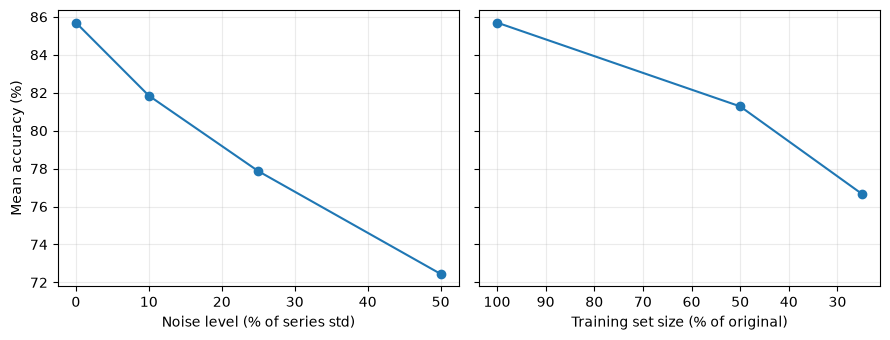

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import spearmanr, wilcoxon

OUTPUT_DIR = Path("/Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series") / "minirocket_robustness_results"
results = pd.read_csv(OUTPUT_DIR / "robustness_results.csv")

per_dataset = results.groupby(["dataset", "condition"])["accuracy"].mean().unstack().dropna()
info = results[results["condition"] == "clean"].groupby("dataset").agg(
    series_length=("series_length", "first"), n_train=("n_train", "first"), n_classes=("n_classes", "first"))
info["train_per_class"] = info["n_train"] / info["n_classes"]
info = info.loc[per_dataset.index]

order = ["clean", "noise_0.10", "noise_0.25", "noise_0.50", "train_50%", "train_25%"]
order = [c for c in order if c in per_dataset.columns]
rows = []
for condition in order:
    difference = per_dataset[condition] - per_dataset["clean"]
    try:
        p_value = float("nan") if condition == "clean" else wilcoxon(per_dataset[condition], per_dataset["clean"]).pvalue
    except ValueError:  # every difference is zero
        p_value = 1.0
    rows.append({
        "condition": condition,
        "mean_accuracy_%": 100 * per_dataset[condition].mean(),
        "change_vs_clean_points": 100 * difference.mean(),
        "median_change_points": 100 * difference.median(),
        "wins": int((difference > 0.0005).sum()),
        "draws": int((difference.abs() <= 0.0005).sum()),
        "losses": int((difference < -0.0005).sum()),
        "wilcoxon_p_vs_clean": p_value,
    })
summary = pd.DataFrame(rows)
summary.to_csv(OUTPUT_DIR / "robustness_summary.csv", index=False)
print(f"{len(per_dataset)} datasets with all conditions complete")
display(summary.round(4))

print("\nDatasets losing the most accuracy (percentage points):")
for condition in ("noise_0.50", "train_25%"):
    if condition in per_dataset:
        drop = (100 * (per_dataset["clean"] - per_dataset[condition])).sort_values(ascending=False)
        print(f"  {condition}: " + ", ".join(f"{d} ({v:.1f})" for d, v in drop.head(8).items()))

print("\nSpearman correlation of accuracy loss with dataset properties:")
for condition in ("noise_0.50", "train_25%"):
    if condition in per_dataset:
        drop = per_dataset["clean"] - per_dataset[condition]
        for prop in ("series_length", "train_per_class"):
            rho, p = spearmanr(drop, info[prop])
            print(f"  {condition} vs {prop}: rho = {rho:.2f}, p = {p:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
noise = summary[summary["condition"].str.startswith("noise") | (summary["condition"] == "clean")]
axes[0].plot([0, 10, 25, 50][:len(noise)], noise["mean_accuracy_%"], "o-")
axes[0].set_xlabel("Noise level (% of series std)")
axes[0].set_ylabel("Mean accuracy (%)")
data = summary[summary["condition"].str.startswith("train") | (summary["condition"] == "clean")]
axes[1].plot([100, 50, 25][:len(data)], data["mean_accuracy_%"], "o-")
axes[1].invert_xaxis()
axes[1].set_xlabel("Training set size (% of original)")
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "robustness_curves.png", dpi=300)
plt.show()

## 5. Recording the experimental setup

The settings, dataset list, platform and software versions are saved in `experiment_metadata.json` alongside the results.

In [5]:
from importlib.metadata import PackageNotFoundError, version


def package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


metadata = {
    "recorded_local_time": time.strftime("%Y-%m-%d %H:%M:%S"),
    "experiment": EXPERIMENT_NAME,
    "settings": EXPERIMENT_SETTINGS,
    "datasets": [name for name, _, _ in dataset_paths],
    "numba_threads": numba.get_num_threads(),
    "platform": platform.platform(),
    "python": sys.version.split()[0],
    "software_versions": {p: package_version(p) for p in ("numpy", "pandas", "scikit-learn", "scipy", "aeon", "numba")},
}
(OUTPUT_DIR / "experiment_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Metadata saved to:", OUTPUT_DIR / "experiment_metadata.json")

Metadata saved to: /Users/uchhasdewan/Downloads/UCD-academics/projects/ai-for-time-series/minirocket_robustness_results/experiment_metadata.json
